# Word Vectors and Job Categories - Exercise

**Business problem:** suggest one of four categories for a publisher to review.

A model supports a decision; it does not make the business decision for us.

Start with the [spam worked example in the concept notebook](text_embeddings_concept.ipynb). Here we transfer its text → word vectors → document mean → classifier workflow to job categories. Unlike the spam example's invented vectors, this exercise learns word2vec from training text.

## Learning objectives

- Compare a text representation with frequency and TF-IDF baselines.
- Keep fitting, validation selection and final evaluation separate.
- Interpret errors and limits before proposing a business use.

## Dataset and practical scope

120 original synthetic German ads: 72 train, 24 validation, 24 test, ordered by constructed date. IDs and dates are not model features. Shared simple templates make this easier than a real job market. The measured results here do not reproduce the real-data slides.

Complete the `None` values marked `# TODO` before running the affected cells. Replace the answer prompts with one or two sentences.

## Libraries and settings

Use the prepared Python 3.11 Codespace kernel. No GPU or API key is needed.

In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 7
np.random.seed(SEED)
DATA_ROOT = Path('../../../00_Data')

## 1. Minimal data inspection

Read the supplied CSV and retain its fixed chronological partitions.

In [15]:
jobs = pd.read_csv(DATA_ROOT / 'nlp_teaching_jobs.csv', parse_dates=['creation_date'])
parts = {name: jobs[jobs['split'] == name].copy()
         for name in ['train', 'validation', 'test']}
display(jobs[['text', 'category', 'split']].head(4))
display(jobs.groupby(['split', 'category']).size().unstack())

,text,category,split
0,Du betreibst ETL-Prozesse. Du arbeitest mit Ai...,Data engineering,train
1,Du entwickelst Webanwendungen. Du arbeitest mi...,Software development,train
2,Du bearbeitest Reklamationen. Du arbeitest mit...,Customer service,train
3,Du prüfst Rechnungen. Du arbeitest mit Excel u...,Accounting,train


category,Accounting,Customer service,Data engineering,Software development
split,,,,
test,6,6,6,6
train,18,18,18,18
validation,6,6,6,6


## 2. Business and statistical baseline

A frequency baseline ignores text. TF-IDF plus logistic regression is a stronger lexical baseline. Fit vocabulary and IDF on training ads only.

In [16]:
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

y_train = parts['train']['category']
y_validation = parts['validation']['category']
y_test = parts['test']['category']
prior = DummyClassifier(strategy='prior').fit(np.zeros((len(y_train), 1)), y_train)
tfidf = TfidfVectorizer(ngram_range=(1, 2))
lexical = {name: tfidf.fit_transform(frame['text']) if name == 'train'
           else tfidf.transform(frame['text']) for name, frame in parts.items()}

## 3. Learn word vectors from training text

The supplied small skip-gram network predicts nearby words with full softmax, as in the lecture. The class labels are not used for word-vector learning. A batch contains centre/neighbor pairs; an epoch visits all pairs. This tiny corpus cannot establish general semantic understanding.

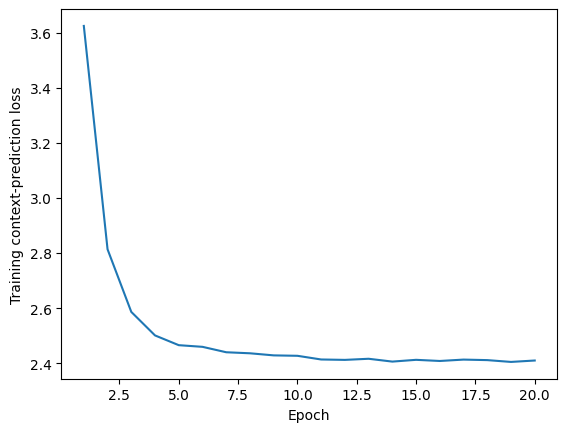

In [17]:
import re
import torch
from torch import nn

torch.manual_seed(SEED)
torch.set_num_threads(2)
tokens = [re.findall(r"[^\W\d_]+", text.lower())
          for text in parts['train']['text']]
vocabulary = sorted({word for sentence in tokens for word in sentence})
word_id = {word: i for i, word in enumerate(vocabulary)}
pairs = []
for sentence in tokens:
    ids = [word_id[word] for word in sentence]
    for centre, word in enumerate(ids):
        for neighbour in range(max(0, centre - 2), min(len(ids), centre + 3)):
            if neighbour != centre:
                pairs.append((word, ids[neighbour]))
pairs = torch.tensor(pairs, dtype=torch.long)

class SkipGram(nn.Module):
    def __init__(self, size, dimensions=24):
        super().__init__()
        self.words = nn.Embedding(size, dimensions)
        self.context = nn.Linear(dimensions, size, bias=False)

    def forward(self, centres):
        return self.context(self.words(centres))

word_model = SkipGram(len(vocabulary))
optimizer = torch.optim.Adam(word_model.parameters(), lr=0.02)
loss_function = nn.CrossEntropyLoss()
losses = []
for epoch in range(20):
    order = torch.randperm(len(pairs))
    batch_losses = []
    for batch in order.split(128):
        centres, neighbours = pairs[batch].T
        optimizer.zero_grad()
        loss = loss_function(word_model(centres), neighbours)
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())
    losses.append(np.mean(batch_losses))
plt.plot(range(1, 21), losses)
plt.xlabel('Epoch')
plt.ylabel('Training context-prediction loss')
plt.show()
lookup = word_model.words.weight.detach().numpy()

## 4. Average known word vectors

**Coding task:** compute the coordinate-wise mean of `known` using NumPy and `axis=0`. The supplied function skips unknown words but explicitly reports an entirely unrepresented text.

In [18]:
def document_mean(text):
    words = re.findall(r"[^\W\d_]+", text.lower())
    known = [lookup[word_id[word]] for word in words if word in word_id]
    if not known:
        raise ValueError('This text contains no known words; it needs another representation or review.')
    mean = None  # TODO: coordinate-wise mean of known word vectors
    return mean

vectors = {name: np.vstack([document_mean(text) for text in frame['text']])
           for name, frame in parts.items()}
print('Training vector matrix:', vectors['train'].shape)

Training vector matrix: (72, 1)


### Interpret the result

Can falling context-prediction loss establish better category decisions?

**Your interpretation:** Replace this sentence with your answer.

## 5. Train and select the category classifier

**Coding task:** create `LogisticRegression(C=regularization, max_iter=600, random_state=SEED)`. The supplied loop compares C=0.3 and C=1 using validation macro-F1, giving each category equal weight. Choose the smaller C on a tie. Scaling is fitted on training vectors only.

In [19]:
representations = {'TF-IDF': lexical, 'word2vec': vectors}
chosen = {}
validation_rows = []
for name, matrices in representations.items():
    candidates = []
    for regularization in [0.3, 1.0]:
        classifier = LogisticRegression(C=regularization, max_iter=600, random_state=SEED)  # TODO: logistic-regression estimator with the requested settings
        model = (make_pipeline(StandardScaler(), classifier)
                 if name == 'word2vec' else classifier)
        model.fit(matrices['train'], y_train)
        score = f1_score(y_validation, model.predict(matrices['validation']), average='macro')
        candidates.append((score, regularization, model))
        validation_rows.append({'model': name, 'C': regularization, 'validation macro-F1': score})
    candidates.sort(key=lambda item: (-item[0], item[1]))
    chosen[name] = candidates[0][2]
display(pd.DataFrame(validation_rows))

/home/vscode/.local/lib/python3.11/site-packages/sklearn/utils/extmath.py:1101: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
/home/vscode/.local/lib/python3.11/site-packages/sklearn/utils/extmath.py:1106: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
/home/vscode/.local/lib/python3.11/site-packages/sklearn/utils/extmath.py:1126: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

## 6. Evaluate fixed choices

Do not change settings after seeing these test results. Accuracy counts correct first labels; macro-F1 weights categories equally.

In [ ]:
test_predictions = {'Frequency': prior.predict(np.zeros((len(y_test), 1)))}
for name, model in chosen.items():
    test_predictions[name] = model.predict(representations[name]['test'])
results = [{'model': name,
            'accuracy': accuracy_score(y_test, prediction),
            'macro-F1': f1_score(y_test, prediction, average='macro')}
           for name, prediction in test_predictions.items()]
display(pd.DataFrame(results).set_index('model').round(3))

### Interpret the result

Which recipe would you investigate further? What prevents a deployment claim?

**Your interpretation:** Replace this sentence with your answer.

## Interpretation: inspect individual decisions

A confusion matrix and a few predictions help identify errors; do not interpret estimated category probabilities as calibrated truth.

In [ ]:
prediction = test_predictions['word2vec']
ConfusionMatrixDisplay.from_predictions(y_test, prediction, xticks_rotation=35)
plt.show()
display(parts['test'][['text', 'category']].assign(predicted=prediction).head(6))

## Summary and business implications

Select with validation evidence, evaluate fixed recipes, then connect errors to publisher review. Changing representations is not a controlled causal experiment.

## Limitations

This is a small teaching example, not evidence of deployment performance. Keep evaluation separate from fitting and model selection. Check errors and the user's decision, not only a headline metric.

## Further exercises

- Inspect mistakes rather than only the mean score.
- What happens to unknown words or truncated requirements?
- Optional: use an authorized real dataset with a documented chronological split; do not redistribute private text.

## References

**Required reading:** Stanford CS224N, Spring 2024, word-vector lecture, supplied excerpt.
**Instructor reference:** Mikolov et al. (2013), *Efficient Estimation of Word Representations in Vector Space*.
https://arxiv.org/abs/1301.3781
**Official documentation:** https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction

### Jupyter notebook - footer info

Include your name, submission date and a short description of your changes when submitting.